In [1]:
import pandas as pd

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
df=pd.read_csv(r"student_performance_dataset_6000_real_names.csv")

In [5]:
df

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status
0,Kimberly Flores,NaN,74,69,74,NaN,48530.0,Yes,6.3,Placed
1,George Williams,79.0,46,60,65,Music,92980.0,No,4.3,Placed
2,Paul Nguyen,96.9,70,94,88,Sports,81558.0,Yes,6.7,Placed
3,Laura Moore,90.2,52,57,80,Sports,71822.0,Yes,4.4,Not Placed
4,Angela Harris,NaN,67,80,76,Sports,10745.0,Yes,4.6,Placed
...,...,...,...,...,...,...,...,...,...,...
6095,Joshua Garcia,87.6,64,67,59,Volunteer,59107.0,No,4.7,Placed
6096,Linda Rodriguez,66.6,46,70,100,Debate,56111.0,Yes,8.3,Placed
6097,Kevin Martinez,85.6,57,57,59,Debate,18921.0,Yes,4.1,Not Placed
6098,Ronald Gonzalez,86.4,71,77,75,Sports,103331.0,Yes,5.8,Placed


## Phase1:Data understanding

In [7]:
df.head()

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status
0,Kimberly Flores,NaN,74,69,74,NaN,48530.0,Yes,6.3,Placed
1,George Williams,79.0,46,60,65,Music,92980.0,No,4.3,Placed
2,Paul Nguyen,96.9,70,94,88,Sports,81558.0,Yes,6.7,Placed
3,Laura Moore,90.2,52,57,80,Sports,71822.0,Yes,4.4,Not Placed
4,Angela Harris,NaN,67,80,76,Sports,10745.0,Yes,4.6,Placed


In [9]:
df.shape

(6100, 10)

In [10]:
df.tail()

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status
6095,Joshua Garcia,87.6,64,67,59,Volunteer,59107.0,No,4.7,Placed
6096,Linda Rodriguez,66.6,46,70,100,Debate,56111.0,Yes,8.3,Placed
6097,Kevin Martinez,85.6,57,57,59,Debate,18921.0,Yes,4.1,Not Placed
6098,Ronald Gonzalez,86.4,71,77,75,Sports,103331.0,Yes,5.8,Placed
6099,Edward Wilson,87.8,80,81,91,Sports,124645.0,Yes,5.6,Placed


In [11]:
df.columns

Index(['Student Name', 'Attendance %', 'Internal Marks', 'Final Marks',
       'Assignment Scores', 'Extra Activities', 'Family Income',
       'Internet Access', 'Study Hours', 'Placement Status'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6100 entries, 0 to 6099
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Student Name       6100 non-null   object 
 1   Attendance %       5798 non-null   float64
 2   Internal Marks     6100 non-null   int64  
 3   Final Marks        6100 non-null   object 
 4   Assignment Scores  6100 non-null   int64  
 5   Extra Activities   5124 non-null   object 
 6   Family Income      5850 non-null   float64
 7   Internet Access    6100 non-null   object 
 8   Study Hours        6100 non-null   float64
 9   Placement Status   6100 non-null   object 
dtypes: float64(3), int64(2), object(5)
memory usage: 476.7+ KB


In [13]:
df.describe()

,Attendance %,Internal Marks,Assignment Scores,Family Income,Study Hours
count,5798.000000,6100.000000,6100.000000,5850.000000,6100.000000
mean,79.882442,63.924262,73.174918,65598.278974,5.507213
std,11.390175,63.485575,18.610559,27690.948326,1.948208
min,37.900000,-15.000000,5.000000,8000.000000,1.000000
25%,72.200000,49.000000,60.000000,46347.000000,4.100000
50%,80.100000,60.000000,74.000000,64715.500000,5.500000
75%,88.100000,71.000000,88.000000,84305.000000,6.900000
max,100.000000,999.000000,100.000000,180471.000000,10.000000


In [15]:
df.isnull().sum()

Student Name           0
Attendance %         302
Internal Marks         0
Final Marks            0
Assignment Scores      0
Extra Activities     976
Family Income        250
Internet Access        0
Study Hours            0
Placement Status       0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(100)

In [17]:
## to see the few duplicated values


In [20]:
duplicates=df[df.duplicated()]
duplicates.head()

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status
6000,Emily Jones,80.2,83,85,77,Debate,94377.0,Yes,7.0,Placed
6001,Donald Jackson,98.6,64,82,77,Volunteer,46877.0,No,6.1,Placed
6002,Joshua Wright,69.5,66,C,71,Sports,95784.0,No,5.3,Not Placed
6003,Joseph Lopez,73.6,67,61,77,Sports,88888.0,Yes,6.7,Placed
6004,Mary Garcia,81.3,57,C,40,Sports,76604.0,Yes,2.1,Not Placed


## Phase2:Data Cleaning

In [21]:
## remove duplicate record from the dataset

In [22]:
df=df.drop_duplicates()

In [24]:
df.duplicated().sum() # verify if there is any more duplicate or not

np.int64(0)

In [27]:
df.shape

(6000, 10)

In [25]:
# check and handle missing value

In [26]:
df.isnull().sum()

Student Name           0
Attendance %         300
Internal Marks         0
Final Marks            0
Assignment Scores      0
Extra Activities     959
Family Income        250
Internet Access        0
Study Hours            0
Placement Status       0
dtype: int64

In [28]:
## for numeric data we use median 
# and for catogorical object we use mode

In [29]:
df["Attendance %"].median()

np.float64(80.0)

In [30]:
df["Family Income"].median()

np.float64(64702.0)

In [32]:
df["Extra Activities"].mode()

0    Sports
Name: Extra Activities, dtype: object

## Handling Missing Values

## Missing values were identified in three columns:

### -Attendance % was filled using the median (80.0) because the median is less affected by extreme values.
### -Family Income was filled using the median (64,702) because income data is often skewed.
### - Extra Activities was filled using the mode ("Sports") because it is a categorical feature.

In [33]:
# now filling the missing value using fillna

In [34]:
df["Attendance %"]=df["Attendance %"].fillna(df["Attendance %"].median())

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\1673132199.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Attendance %"]=df["Attendance %"].fillna(df["Attendance %"].median())


In [35]:
df["Family Income"]=df["Family Income"].fillna(df["Family Income"].median())

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\3347435755.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Family Income"]=df["Family Income"].fillna(df["Family Income"].median())


In [37]:
df["Extra Activities"]=df["Extra Activities"].fillna(df["Extra Activities"].mode()[0])

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\2652341482.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Extra Activities"]=df["Extra Activities"].fillna(df["Extra Activities"].mode()[0])


In [38]:
# to verify weather there is any null value is still present or not

In [39]:
df.isnull().sum()

Student Name         0
Attendance %         0
Internal Marks       0
Final Marks          0
Assignment Scores    0
Extra Activities     0
Family Income        0
Internet Access      0
Study Hours          0
Placement Status     0
dtype: int64

In [40]:
# checking the data type in the dataset as they are in correct form or not

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Student Name       6000 non-null   object 
 1   Attendance %       6000 non-null   float64
 2   Internal Marks     6000 non-null   int64  
 3   Final Marks        6000 non-null   object 
 4   Assignment Scores  6000 non-null   int64  
 5   Extra Activities   6000 non-null   object 
 6   Family Income      6000 non-null   float64
 7   Internet Access    6000 non-null   object 
 8   Study Hours        6000 non-null   float64
 9   Placement Status   6000 non-null   object 
dtypes: float64(3), int64(2), object(5)
memory usage: 515.6+ KB


In [42]:
# final marks is in object lets see ehy it is object

In [44]:
df["Final Marks"].value_counts()

Final Marks
69    169
66    162
72    155
68    151
67    143
     ... 
25      3
18      1
20      1
13      1
15      1
Name: count, Length: 88, dtype: int64

In [45]:
df["Final Marks"].unique()

array(['69', '60', '94', '57', '80', '90', '77', '58', '87', '76', '92',
       '66', '88', '47', '55', '50', '54', '46', '79', '74', '63', '67',
       '62', '70', '72', '64', '49', 'Absent', '73', '71', '59', '84',
       '78', '43', 'B', '65', '68', '81', '44', '97', '61', '83', '56',
       '91', '38', '89', '82', '52', 'C', '53', '100', '37', 'A', '75',
       '45', '22', '41', '48', '85', '39', '51', '86', '99', '96', '98',
       '29', '93', '33', '36', '42', '95', '31', '23', '40', '32', '24',
       '34', '30', '26', '21', '18', '28', '35', '27', '25', '20', '13',
       '15'], dtype=object)

In [46]:
df["Final Marks"].value_counts()

Final Marks
69    169
66    162
72    155
68    151
67    143
     ... 
25      3
18      1
20      1
13      1
15      1
Name: count, Length: 88, dtype: int64

In [47]:
## to see where that A,B,C,ABsent is located

In [49]:
df["Final Marks"].value_counts().loc[["A","B","C","Absent"]]

Final Marks
A         101
B          78
C          73
Absent     98
Name: count, dtype: int64

In [50]:
## since the final marks datatype should be numeric to change it to integer we need to replace A=90,B=80,C=70 and absent=0

In [51]:
df["Final Marks"]=df["Final Marks"].replace({
    "A":90,
    "B":80,
    "C":70,
    "Absent":0
})

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\3387304239.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Final Marks"]=df["Final Marks"].replace({


In [52]:
df["Final Marks"]=df["Final Marks"].astype(int)

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\1059857403.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Final Marks"]=df["Final Marks"].astype(int)


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Student Name       6000 non-null   object 
 1   Attendance %       6000 non-null   float64
 2   Internal Marks     6000 non-null   int64  
 3   Final Marks        6000 non-null   int64  
 4   Assignment Scores  6000 non-null   int64  
 5   Extra Activities   6000 non-null   object 
 6   Family Income      6000 non-null   float64
 7   Internet Access    6000 non-null   object 
 8   Study Hours        6000 non-null   float64
 9   Placement Status   6000 non-null   object 
dtypes: float64(3), int64(3), object(4)
memory usage: 515.6+ KB


In [54]:
## checking outliers in marks

### Outlier Analysis

#### Boxplots were created for Internal Marks, Final Marks, and Assignment Scores to detect potential outliers.

#### A few low-score outliers were identified. These values were retained because they represent genuine student performance rather than data entry errors. Keeping them is important for identifying at-risk students and performing realistic educational analysis.

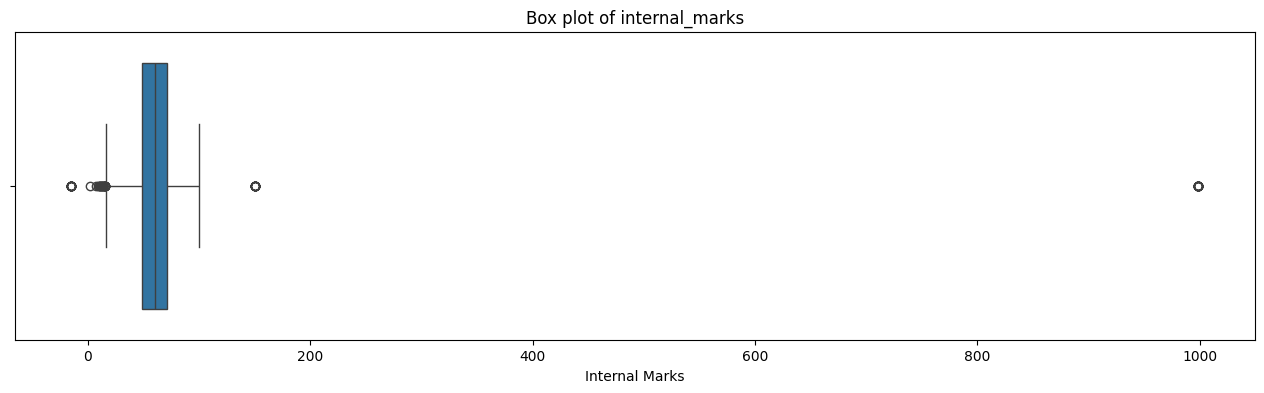

In [61]:
plt.figure(figsize=(16,4))
sns.boxplot(x=df["Internal Marks"])
plt.title("Box plot of internal_marks")
plt.show()

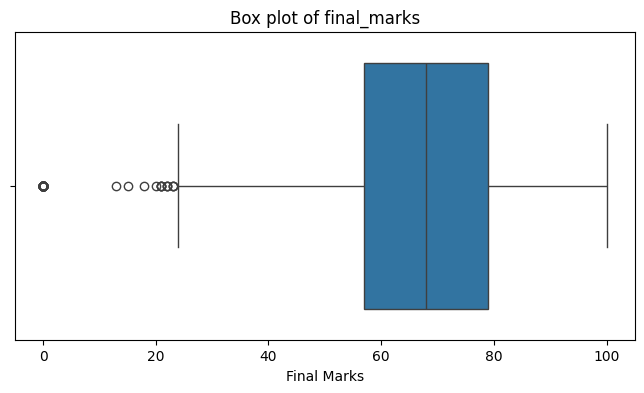

In [67]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Final Marks"])
plt.title("Box plot of final_marks")
plt.show()

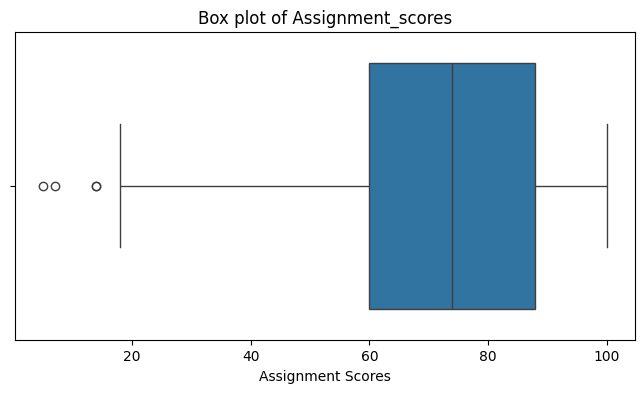

In [66]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Assignment Scores"])
plt.title("Box plot of Assignment_scores")
plt.show()

## Phase3:EDA

In [68]:
## statistical summary

In [69]:
df.describe()

,Attendance %,Internal Marks,Final Marks,Assignment Scores,Family Income,Study Hours
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,79.884417,64.000333,66.756667,73.192000,65537.405833,5.506667
std,11.124276,63.972682,17.117660,18.555337,27113.884023,1.942863
min,37.900000,-15.000000,0.000000,5.000000,8000.000000,1.000000
25%,72.600000,49.000000,57.000000,60.000000,47091.000000,4.100000
50%,80.000000,60.000000,68.000000,74.000000,64702.000000,5.500000
75%,87.600000,71.000000,79.000000,88.000000,83310.500000,6.900000
max,100.000000,999.000000,100.000000,100.000000,180471.000000,10.000000


In [70]:
# here in internal marks min value is negative and max value is above 100 which need to fixed

In [71]:
df[df["Internal Marks"]<0]

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status
679,Jennifer Garcia,95.8,-15,66,69,Debate,32046.0,No,5.2,Placed
920,Amanda Clark,80.1,-15,50,63,NCC,63314.0,No,4.7,Not Placed
1157,Patricia Taylor,66.8,-15,84,100,Volunteer,34306.0,Yes,7.0,Placed
1171,Jessica Clark,68.5,-15,81,88,NCC,29198.0,Yes,5.3,Placed
1925,Susan Wilson,92.4,-15,51,64,Sports,37646.0,Yes,3.4,Not Placed
2095,Sandra Sanchez,86.4,-15,41,47,Music,14691.0,No,2.6,Not Placed
2727,Sandra Jackson,77.3,-15,57,55,Music,33909.0,Yes,3.3,Not Placed
2880,Rebecca Thompson,87.7,-15,57,43,Sports,41623.0,No,3.7,Not Placed
3644,Emma Lewis,76.5,-15,63,55,Music,44425.0,No,3.7,Placed
3651,Stephanie Johnson,67.6,-15,41,45,Debate,55693.0,Yes,2.1,Not Placed


In [72]:
df[df["Internal Marks"]>100]

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status
168,Nancy Robinson,52.1,150,52,72,Music,45382.0,Yes,3.7,Not Placed
175,Nicholas Allen,81.3,150,68,75,Volunteer,85294.0,No,6.7,Placed
295,Angela Hill,79.1,999,71,73,Sports,23833.0,No,5.9,Placed
363,Brian Ramirez,74.1,999,75,39,Volunteer,152512.0,Yes,2.9,Placed
721,Linda Perez,81.4,150,76,65,Debate,78596.0,No,5.3,Placed
998,Karen Brown,82.8,999,65,73,Sports,52835.0,No,5.3,Placed
1174,Steven Thompson,71.0,999,67,78,Music,92643.0,No,6.5,Placed
1351,Sandra Robinson,81.6,150,58,40,NCC,27085.0,Yes,2.4,Not Placed
2090,Michelle Walker,80.6,999,80,74,Volunteer,28452.0,Yes,7.4,Placed
2269,Daniel Robinson,88.3,999,89,89,Volunteer,71314.0,Yes,6.3,Placed


In [ ]:
## since there are too many outlier in internalmarks we need tto replace them by taking median of valid marks

In [80]:
valid_marks=df[(df["Internal Marks"]>0)
& (df["Internal Marks"]<100)]["Internal Marks"].median()



In [81]:
valid_marks

np.float64(60.0)

In [84]:
df["Internal Marks"]=df["Internal Marks"].replace({
    -15:valid_marks,
    999:valid_marks})

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\3776140182.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Internal Marks"]=df["Internal Marks"].replace({


In [85]:
## we can replace same thing by other way too

In [86]:
df.loc[df["Internal Marks"] <0,["Internal Marks"]]=valid_marks
df.loc[df["Internal Marks"] >100,["Internal Marks"]]=valid_marks

In [88]:
df[df["Internal Marks"]>100]

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status


In [89]:
df[df["Internal Marks"] <0]

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status


## Actual EDA process

In [90]:
## draw histogram to visualize the numeric columns

In [ ]:
## Most students maintain good attendance, with the majority attending around 80% of classes. Only a small number of students have very low attendance, indicating that poor attendance is relatively uncommon.
## Internal marks are concentrated around the middle range, with most students scoring between 45 and 70 marks. Extremely low scores are uncommon.
## Final examination marks are centered around the mid-to-high range, suggesting that most students performed reasonably well in the final assessment.


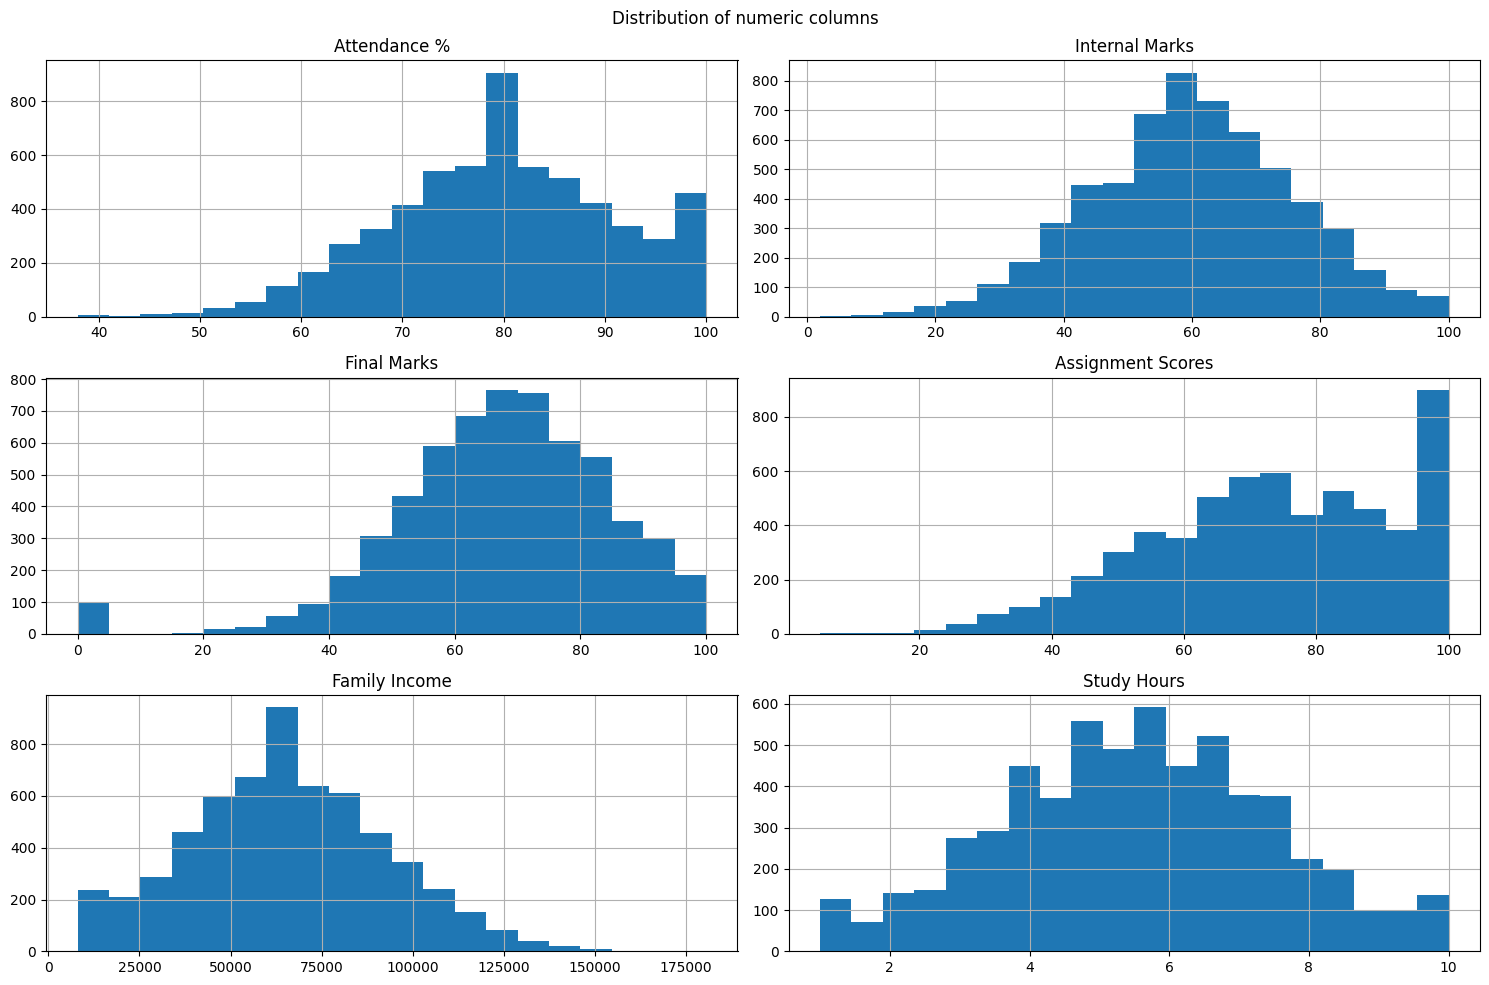

In [91]:
df.hist(figsize=(15,10),bins=20)
plt.suptitle("Distribution of numeric columns")
plt.tight_layout()
plt.show()

In [92]:
# Does attendance affect marks?
# The scatter plot shows a moderate positive relationship between attendance and final marks. 
#Students with higher attendance generally tend to achieve better academic performance.
#However, there is considerable variation in marks at similar attendance levels, 
#indicating that attendance is only one of several factors influencing student performance.

In [93]:
# Attendence Vs Final Marks

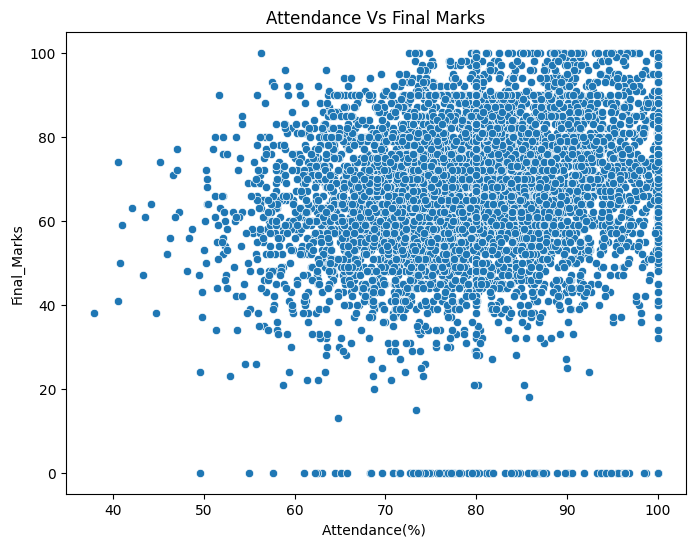

In [100]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=df["Attendance %"],
                y=df["Final Marks"])
alpha=0.5
plt.title("Attendance Vs Final Marks")
plt.xlabel("Attendance(%) ")
plt.ylabel("Final_Marks")
plt.show()

In [101]:
df[df["Final Marks"] == 0].shape

(98, 10)

In [98]:
## study hrs vs finalmarks

In [ ]:
#Observation: The scatter plot shows a clear positive relationship between study hours and final marks. 
#Students who spend more time studying generally achieve higher scores.
#However, the variation in marks among students with similar study hours suggests that additional factors also influence academic performance.

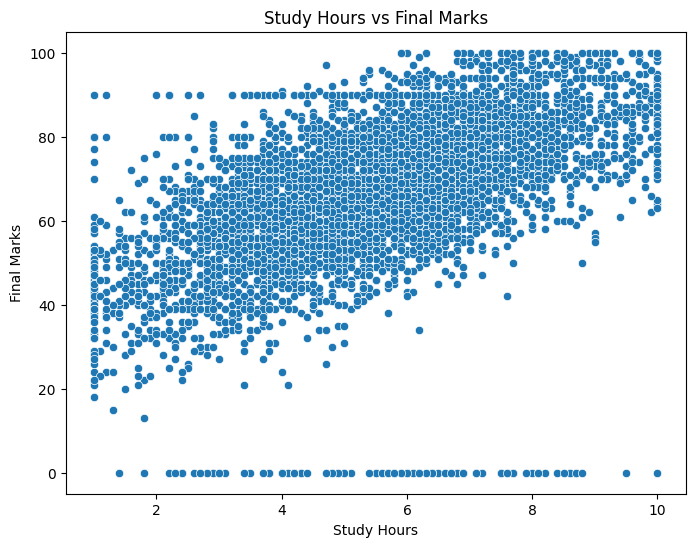

In [99]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Study Hours",
    y="Final Marks"
)

plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.show()

In [102]:
#Does internet access improve scores?
#Students with internet access have a slightly higher median final mark, but the distributions are very similar. 
#Therefore, internet access may help academic performance, but it is not the strongest factor affecting final marks.

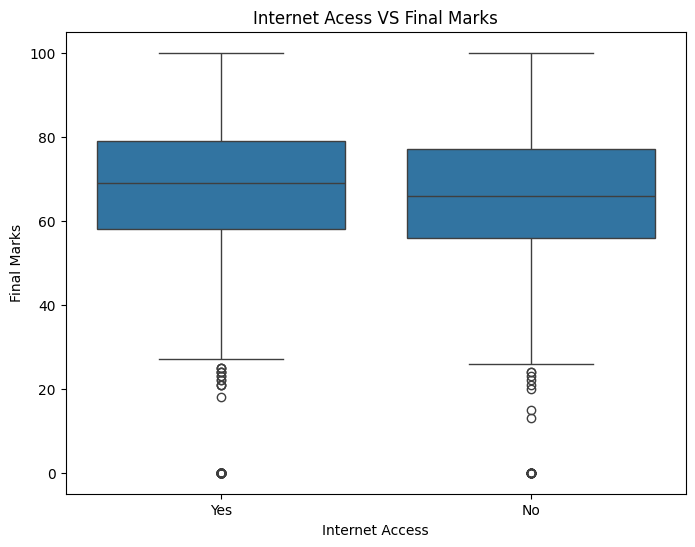

In [104]:
plt.figure(figsize=(8,6))
sns.boxplot(x=df["Internet Access"],
            y=df["Final Marks"])
plt.title("Internet Acess VS Final Marks")
plt.xlabel("Internet Access")
plt.ylabel("Final Marks")
plt.show()

In [105]:
#Does Family Income Affect Student Performance?
#=Observation: The scatter plot shows no strong correlation between family income and final marks. 
#Students from both lower- and higher-income families achieved a wide range of scores, 
#suggesting that family income alone is not a major determinant of academic performance.

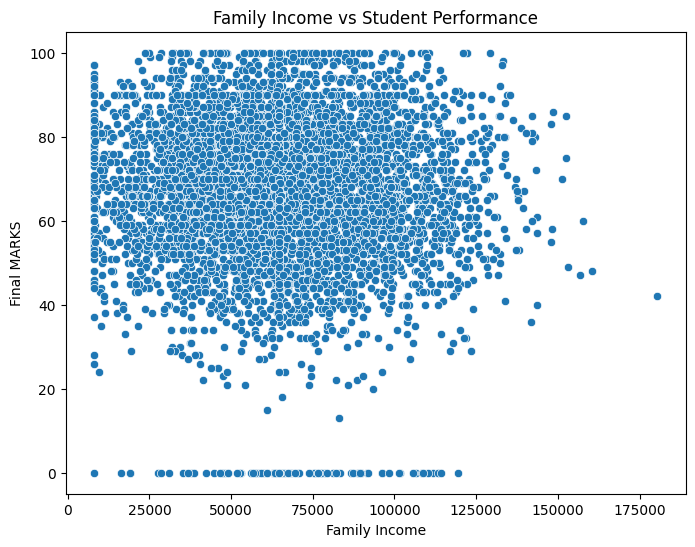

In [107]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=df["Family Income"],
                 y=df["Final Marks"]
                )
plt.title("Family Income vs Student Performance")
plt.xlabel("Family Income")
plt.ylabel("Final MARKS")
plt.show()


In [108]:
# drawing heatmap to show how strongly the numerical columns are related to each other

In [ ]:
#Observation: The correlation heatmap indicates that Internal Marks (0.64), Assignment Scores (0.57), 
#and Study Hours (0.56) have moderate to strong positive relationships with Final Marks. 
#Attendance shows only a weak positive correlation (0.20), while Family Income has almost no correlation (-0.02). 
#This suggests that academic performance is more closely associated with students' study habits 
#and continuous assessments than with family income.

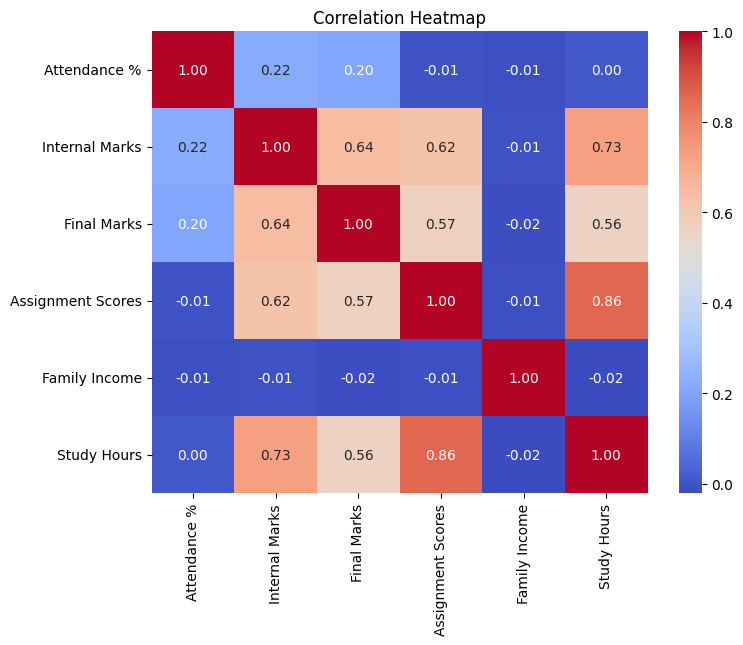

In [109]:
plt.figure(figsize=(8,6))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## Phase4:Feature Engineering

In [110]:
#creating average score

In [114]:
df["Average_Score"]=(
    df["Final Marks"]+
    df["Internal Marks"]+
    df["Assignment Scores"])/3

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\1918623840.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Average_Score"]=(


In [115]:
df["Average_Score"]

0       72.333333
1       57.000000
2       84.000000
3       63.000000
4       74.333333
          ...    
5995    84.666667
5996    52.333333
5997    52.000000
5998    75.666667
5999    72.666667
Name: Average_Score, Length: 6000, dtype: float64

In [116]:
df.head()

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status,Average_Score
0,Kimberly Flores,80.0,74,69,74,Sports,48530.0,Yes,6.3,Placed,72.333333
1,George Williams,79.0,46,60,65,Music,92980.0,No,4.3,Placed,57.000000
2,Paul Nguyen,96.9,70,94,88,Sports,81558.0,Yes,6.7,Placed,84.000000
3,Laura Moore,90.2,52,57,80,Sports,71822.0,Yes,4.4,Not Placed,63.000000
4,Angela Harris,80.0,67,80,76,Sports,10745.0,Yes,4.6,Placed,74.333333


In [117]:
#Create Risk Category

In [118]:
def risk_category(score):
    if score < 40:
        return "At Risk"
    elif score <60:
        return "Need Improvement"
    else:
        return "Safe"
        


In [119]:
risk_category(40)

'Need Improvement'

In [120]:
df["Risk Category"]=df["Average_Score"].apply(risk_category)

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\2420128177.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Risk Category"]=df["Average_Score"].apply(risk_category)


In [121]:
df.head()

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status,Average_Score,Risk Category
0,Kimberly Flores,80.0,74,69,74,Sports,48530.0,Yes,6.3,Placed,72.333333,Safe
1,George Williams,79.0,46,60,65,Music,92980.0,No,4.3,Placed,57.000000,Need Improvement
2,Paul Nguyen,96.9,70,94,88,Sports,81558.0,Yes,6.7,Placed,84.000000,Safe
3,Laura Moore,90.2,52,57,80,Sports,71822.0,Yes,4.4,Not Placed,63.000000,Safe
4,Angela Harris,80.0,67,80,76,Sports,10745.0,Yes,4.6,Placed,74.333333,Safe


In [122]:
#Create Performance Level

In [135]:
def performance_level(score):
    if score >= 85:
        return "Excellent"
    elif score >=70:
        return "Good"
    elif score >=50:
        return "Average"
    else:
        return "Poor"

In [136]:
df["Performance_Level"]=df["Average_Score"].apply(performance_level)

C:\Users\saris\AppData\Local\Temp\ipykernel_29416\1207758829.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Performance_Level"]=df["Average_Score"].apply(performance_level)


In [137]:
df.head()

,Student Name,Attendance %,Internal Marks,Final Marks,Assignment Scores,Extra Activities,Family Income,Internet Access,Study Hours,Placement Status,Average_Score,Risk Category,Performance_Level
0,Kimberly Flores,80.0,74,69,74,Sports,48530.0,Yes,6.3,Placed,72.333333,Safe,Good
1,George Williams,79.0,46,60,65,Music,92980.0,No,4.3,Placed,57.000000,Need Improvement,Average
2,Paul Nguyen,96.9,70,94,88,Sports,81558.0,Yes,6.7,Placed,84.000000,Safe,Good
3,Laura Moore,90.2,52,57,80,Sports,71822.0,Yes,4.4,Not Placed,63.000000,Safe,Average
4,Angela Harris,80.0,67,80,76,Sports,10745.0,Yes,4.6,Placed,74.333333,Safe,Good


## Phase5:Business Insight

#### Insight 1: Attendance vs Final Marks

We already observed from the scatter plot:

Students with higher attendance generally achieve higher final marks, although the relationship is moderate rather than very strong.

#### Insight 2: Study Hours vs Final Marks

From the scatter plot:

Study hours show a clear positive relationship with final marks. Students who study longer tend to score better.

#### Insight 3: Internet Access

From the boxplot:

Students with internet access have a slightly higher median final mark, but the difference is not very large.

#### Insight 4: Family Income

From the scatter plot and heatmap:

Family income has almost no correlation with academic performance in this dataset.

(Heatmap correlation ≈ -0.02)

#### Insight 5: Internal Marks

From the heatmap:

Internal marks have a strong positive correlation with final marks (≈0.64), indicating that students performing well throughout the semester also tend to perform well in the final examination.

#### Insight 6: Assignment Scores

Correlation ≈0.57

Students with higher assignment scores generally perform better in final examinations.

#### Insight 7: Risk Category

In [127]:
df["Risk Category"].value_counts()

Risk Category
Safe                4067
Need Improvement    1684
At Risk              249
Name: count, dtype: int64

In [129]:
## Most of the student falls into safe caterogy and some need improvement and very few students are at risk

#### Insight 8: Performance Level

In [138]:
df["Performance_Level"].value_counts()

Performance_Level
Average      2592
Good         1961
Poor          793
Excellent     654
Name: count, dtype: int64

In [139]:
## Most of the student falls under the average performance level amd very few are at excellent level

## expoting the cleaned dataset

In [141]:
df.to_csv("Student_Performance_System.csv",index=False)

In [142]:
## to verify

In [143]:
import os
os.listdir()

['.ipynb_checkpoints',
 'student_performance_dataset_6000_real_names.csv',
 'Student_Performance_System.csv',
 'Untitled.ipynb']